# 4. Trends, patterns, and anomalies

The source has no reliable event timestamp suitable for a time trend, so this notebook focuses on segment patterns, IQR outliers, and basic plausibility checks.

In [1]:
import sys
from pathlib import Path

project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(project_root))

import pandas as pd
import seaborn as sns
from src.data_loader import load_data

df = load_data()
df["family_size"] = df["sibsp"] + df["parch"] + 1
display(df.groupby("family_size", observed=True)["survived"].agg(["mean", "count"]))

,mean,count
family_size,,
1,0.303538,537
2,0.552795,161
3,0.578431,102
4,0.724138,29
5,0.200000,15
6,0.136364,22
7,0.333333,12
8,0.000000,6
11,0.000000,7


<Axes: xlabel='family_size', ylabel='survived'>

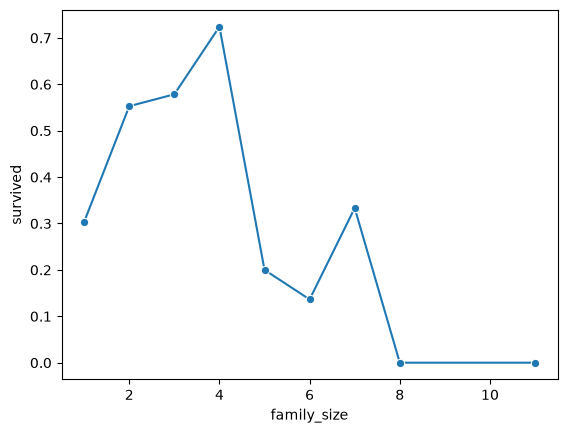

In [2]:
sns.lineplot(data=df, x="family_size", y="survived", estimator="mean", errorbar=None, marker="o")

In [3]:
numeric = ["age", "fare", "sibsp", "parch"]
outlier_summary = []
for column in numeric:
    values = df[column].dropna()
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outlier_summary.append({"column": column, "lower_fence": low, "upper_fence": high,
                            "outlier_count": int(((values < low) | (values > high)).sum())})
display(pd.DataFrame(outlier_summary))

,column,lower_fence,upper_fence,outlier_count
0,age,-6.6875,64.8125,11
1,fare,-26.7240,65.6344,116
2,sibsp,-1.5000,2.5000,46
3,parch,0.0000,0.0000,213


In [4]:
checks = {
    "negative ages": int((df["age"] < 0).sum()),
    "negative fares": int((df["fare"] < 0).sum()),
    "invalid survival labels": int((~df["survived"].isin([0, 1])).sum()),
    "invalid passenger classes": int((~df["pclass"].isin([1, 2, 3])).sum()),
}
checks

{'negative ages': 0,
 'negative fares': 0,
 'invalid survival labels': 0,
 'invalid passenger classes': 0}